In [5]:
%pip install pandas numpy scikit-learn matplotlib ollama

Note: you may need to restart the kernel to use updated packages.


In [6]:
from pathlib import Path
import sys
import ollama
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_squared_error, r2_score

print('Python:', sys.executable)

csv_path = Path('logatta.csv')
if not csv_path.exists():
    raise FileNotFoundError(f'Cannot find {csv_path.resolve()}')

df = pd.read_csv(csv_path)
print('done!', df.shape)
df.info()

target_col = 'accepted for the interview'

df['BusinessTravel'] = df['BusinessTravel'].map({'Non-Travel': 0, 'Travel_Rarely': 1, 'Travel_Frequently': 2})
df['MaritalStatus'] = df['MaritalStatus'].map({'Single': 0, 'Married': 1, 'Divorced': 2})
df['OverTime'] = df['OverTime'].map({'No': 0, 'Yes': 1})
df['Gender'] = df['Gender'].map({'Female': 0, 'Male': 1})
df['accepted for the interview'] = df['accepted for the interview'].astype(str).str.upper().map({'FALSE': 0, 'TRUE': 1})


Python: c:\Users\gevor\AppData\Local\Python\pythoncore-3.14-64\python.exe
done! (1492, 9)
<class 'pandas.DataFrame'>
RangeIndex: 1492 entries, 0 to 1491
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Age                         1492 non-null   int64
 1   BusinessTravel              1492 non-null   str  
 2   Education                   1492 non-null   int64
 3   MaritalStatus               1492 non-null   str  
 4   OverTime                    1492 non-null   str  
 5   EmployeeNumber              1492 non-null   int64
 6   DailyRate                   1492 non-null   int64
 7   Gender                      1492 non-null   str  
 8   accepted for the interview  1492 non-null   bool 
dtypes: bool(1), int64(4), str(4)
memory usage: 94.8 KB


In [10]:

# 1. Clean data
df = df.dropna()

# 2. Encode categorical columns FIRST
label_encoder = LabelEncoder()
for col in df.select_dtypes(include=['object']).columns:
    df[col] = label_encoder.fit_transform(df[col])

# 3. Split features and target AFTER encoding
x = df.iloc[:, 1:2].values  # Note: This only selects ONE column. Is that intended?
y = df.iloc[:, 2].values

# 4. Train/test split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# 5. Initialize, Fit, and THEN access OOB score
regressor = RandomForestRegressor(n_estimators=100, random_state=42, oob_score=True)
regressor.fit(x_train, y_train)

print("Out-of-Bag Score:", regressor.oob_score_)

# 6. Predict and Evaluate
y_pred = regressor.predict(x_test)
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R-squared:", r2_score(y_test, y_pred))

Out-of-Bag Score: -0.034565872811079146
Mean Squared Error: 37417.545287774636
R-squared: -0.6918631025650517


In [11]:


def get_llm_response(model_name, prompt):
    """
    Sends a prompt to the local Ollama instance and returns the response.
    """
    try:
        response = ollama.chat(model=model_name, messages=[
            {
                'role': 'user',
                'content': prompt,
            },
        ])
        return response['message']['content']
    except Exception as e:
        return f"Error connecting to Ollama: {e}"

# Example usage:
model = 'llama3' # or 'mistral', 'phi3', etc.
user_prompt = 'input of RandomForestRegressor with variales needed fix this'

response = get_llm_response(model, user_prompt)
print(f"LLM Response:\n{response}")

LLM Response:
You're trying to use `RandomForestRegressor` from scikit-learn, but you're not sure what variables are required. I'm here to help!

The basic syntax for using `RandomForestRegressor` is:
```python
from sklearn.ensemble import RandomForestRegressor
import numpy as np

# Assuming X_train and y_train are your training data (features and target variable)
X_train = ...  # Your feature matrix (e.g., a pandas DataFrame or NumPy array)
y_train = ...  # Your target variable (e.g., a pandas Series or NumPy array)

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)  # Set hyperparameters as needed

rf_model.fit(X_train, y_train)  # Train the model
```
In this example:

1. `X_train` is your feature matrix (e.g., a pandas DataFrame or NumPy array), which should contain the input variables you want to use for regression.
2. `y_train` is your target variable (e.g., a pandas Series or NumPy array), which represents the output you're trying to predict.
3. `n_estimators` i

--- Line Plot Example ---


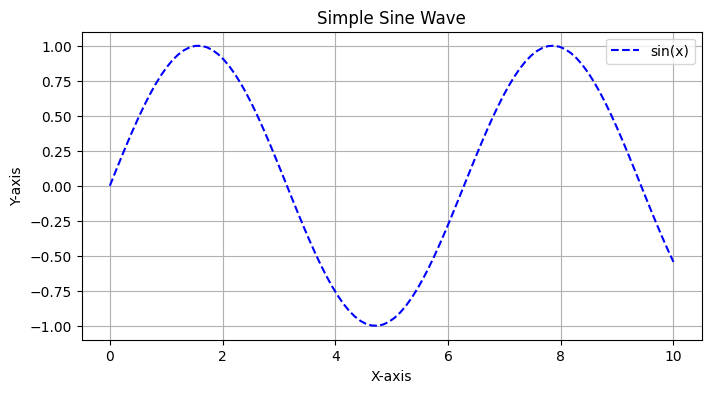


--- Scatter Plot Example ---


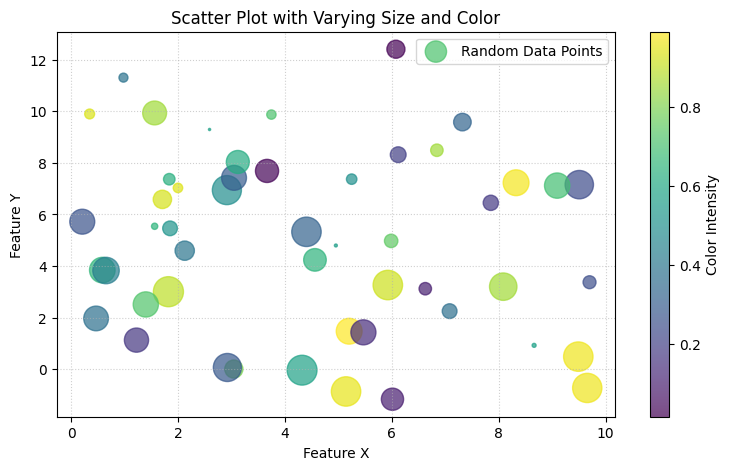

In [ ]:


print("--- Line Plot Example ---")
x = np.linspace(0, 10, 100)
y = np.sin(x)

plt.figure(figsize=(8, 4)) 
plt.plot(x, y, label='sin(x)', color='blue', linestyle='--')
plt.title('Simple Sine Wave')
plt.xlabel('X-axis')
plt.ylabel('Y-axis')
plt.legend()
plt.grid(True)
plt.show()

print("\n--- Scatter Plot Example ---")
np.random.seed(42) 
data = {
    'x_values': np.random.rand(50) * 10,
    'y_values': np.random.rand(50) * 10 + np.random.randn(50) * 2,
    'sizes': np.random.rand(50) * 500,
    'colors': np.random.rand(50)
}
df = pd.DataFrame(data)

plt.figure(figsize=(9, 5))
plt.scatter(df['x_values'], df['y_values'],
            s=df['sizes'], c=df['colors'], cmap='viridis', alpha=0.7,
            label='Random Data Points')
plt.colorbar(label='Color Intensity') # Add a color bar for 'c'
plt.title('Scatter Plot with Varying Size and Color')
plt.xlabel('Feature X')
plt.ylabel('Feature Y')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()